# Cancelamento de reservas de hotel: variáveis do modelo

**Pergunta:** quais reservas têm mais chance de ser canceladas, no momento em que entram?

**Este notebook** parte da base definida no `01_exploratoria.ipynb` (reservas sem depósito, com a limpeza proposta) e decide quais variáveis entram no modelo e de que forma. O modelo e a avaliação ficam no `03_modelo.ipynb`.

Todas as decisões saem do **treino** (chegadas de 2015 e 2016). O teste (2017) só aparece quando a pergunta é se uma relação se mantém no tempo.

## Resumo

*(preenchido ao final da análise)*

- Variáveis que entram, e de que forma: __.
- Variáveis que saem, e por quê: __.

In [1]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.append('..')   # o módulo de funções do projeto fica em analise/
from funcoes_logistica import (CORES, aplicar_estilo, preparar_base,
                               taxa_por_nivel, grafico_taxa_por_nivel,
                               logito_por_faixa, grafico_logito, v_cramer)

aplicar_estilo()
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 80)

## 1. A base do modelo

O escopo e a limpeza vêm do `01_exploratoria.ipynb`: só reservas sem depósito (seção 5.2) e as remoções propostas na seção 4. A função `preparar_base` aplica os dois e acrescenta o total de noites, o total de hóspedes e a marcação de linhas com gêmea idêntica.

In [2]:
hotel = pd.read_csv('../../dados/hotel_bookings.csv')
base, passos = preparar_base(hotel)
display(passos)

treino = base[base['arrival_date_year'] < 2017]
teste = base[base['arrival_date_year'] == 2017]
print('Treino:', len(treino), f"| cancelamento {treino['is_canceled'].mean():.1%}")
print('Teste: ', len(teste), f"| cancelamento {teste['is_canceled'].mean():.1%}")

jan_a_ago = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August']

,reservas,saem neste passo
base inteira,119390,NaN
sem depósito (escopo),104641,14749.0
children preenchido,104637,4.0
com hóspede,104457,180.0
diária entre 0 e 1.000,104456,1.0


Treino: 67990 | cancelamento 26.6%
Teste:  36466 | cancelamento 31.8%


**Leitura.**

- **Ficam 104.456 reservas.** O escopo tira 14.749 com depósito. As remoções tiram mais 185: 4 sem `children`, 180 sem hóspede e a diária negativa. A diária de 5.400 já tinha saído com o escopo (é Non Refund).
- **Treino: 67.990 reservas, 26,6% de cancelamento. Teste: 36.466, 31,8%.**
- As remoções seguem a proposta do notebook 01, seção 4.

## 2. Univariada

**Perguntas:** como cada candidata se distribui? Há variáveis quase constantes, caudas longas ou categorias pequenas demais para estimar? A distribuição muda entre treino e teste?

As distribuições são descritas no **treino**; o teste só entra na comparação do fim da seção.

### 2.1 Numéricas

In [3]:
numericas = ['lead_time', 'adr', 'noites', 'stays_in_weekend_nights', 'stays_in_week_nights',
             'adults', 'children', 'babies', 'previous_cancellations', 'previous_bookings_not_canceled',
             'days_in_waiting_list', 'total_of_special_requests']

def resumo_numerica(s):
    return pd.Series({'pct_zero': (s == 0).mean(), 'p25': s.quantile(.25), 'mediana': s.median(),
                      'p75': s.quantile(.75), 'p95': s.quantile(.95), 'p99': s.quantile(.99), 'max': s.max()})

treino[numericas].apply(resumo_numerica).T.round(4)

,pct_zero,p25,mediana,p75,p95,p99,max
lead_time,0.0657,12.0,50.0,124.0,272.00,351.0000,737.0
adr,0.0208,66.0,90.0,120.0,184.45,239.6522,508.0
noites,0.0079,2.0,3.0,4.0,7.00,14.0000,69.0
stays_in_weekend_nights,0.4274,0.0,1.0,2.0,2.00,4.0000,19.0
stays_in_week_nights,0.0702,1.0,2.0,3.0,5.00,10.0000,50.0
adults,0.0024,2.0,2.0,2.0,3.00,3.0000,55.0
children,0.9259,0.0,0.0,0.0,1.00,2.0000,10.0
babies,0.9903,0.0,0.0,0.0,0.00,0.0000,10.0
previous_cancellations,0.9624,0.0,0.0,0.0,0.00,1.0000,24.0
previous_bookings_not_canceled,0.9681,0.0,0.0,0.0,0.00,3.0000,58.0


**Leitura.**

- **Cinco contagens são quase sempre zero:** `babies` (99,0%), `days_in_waiting_list` (97,7%), `previous_bookings_not_canceled` (96,8%), `previous_cancellations` (96,2%) e `children` (92,6%). Como número, o pouco que não é zero vira cauda (até 58 reservas anteriores mantidas). Se entrarem, entram como sim ou não. `babies` sozinho quase não varia; a bivariada (seção 3.1) mostra se dá para juntar com `children`.
- **`total_of_special_requests`:** 56,3% sem pedido. Candidata a "fez pedido × não fez".
- **`adults`:** o p25 e o p75 são 2, e o máximo é 55. Como número, a cauda pesa mais que o comum. Candidata a "sozinho × acompanhado".

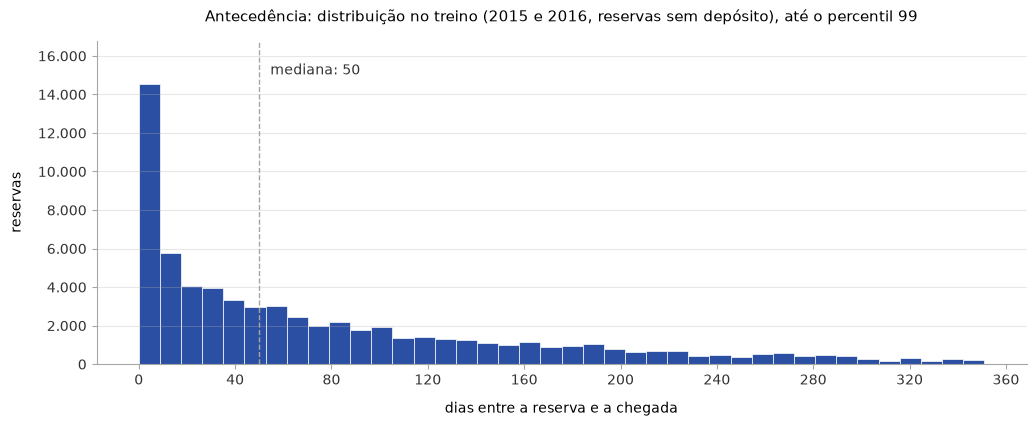

In [4]:
from matplotlib.ticker import FuncFormatter, MaxNLocator, MultipleLocator

milhar = FuncFormatter(lambda x, _: f'{x:,.0f}'.replace(',', '.'))   # 14.000, no padrão brasileiro

# a cauda acima do percentil 99 fica fora do gráfico (está na tabela acima)
def histograma(coluna, titulo, rotulo):
    s = treino[coluna]
    limite = s.quantile(0.99)
    bins = np.arange(0, limite + 2) - 0.5 if coluna == 'noites' else 40
    fig, ax = plt.subplots(figsize=(12, 4.2))
    ax.hist(s[s <= limite], bins=bins, color=CORES['principal'], edgecolor='white', linewidth=0.5)
    ax.axvline(s.median(), color=CORES['referencia'], linestyle='--', linewidth=1)
    # rótulo ao lado do topo da linha da mediana, numa folga acima da barra mais alta
    ax.set_ylim(0, ax.get_ylim()[1] * 1.1)
    ax.annotate(f'mediana: {s.median():.0f}', xy=(s.median(), 0.93), xycoords=ax.get_xaxis_transform(),
                xytext=(8, 0), textcoords='offset points',   # 8 pontos à direita da linha
                fontsize=10, color='#333333', ha='left', va='top',
                bbox=dict(facecolor='white', edgecolor='none', pad=1))
    ax.set_title(f'{titulo}: distribuição no treino (2015 e 2016, reservas sem depósito), até o percentil 99')
    ax.set_xlabel(rotulo)
    ax.set_ylabel('reservas')
    if coluna == 'noites':
        ax.xaxis.set_major_locator(MultipleLocator(1))
        ax.set_xlim(-0.7, limite + 0.7)
    else:
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.yaxis.set_major_formatter(milhar)
    plt.show()


histograma('lead_time', 'Antecedência', 'dias entre a reserva e a chegada')

**Leitura.**

- **`lead_time` tem cauda longa.** Mediana de 50 dias, mas o percentil 99 é 351 e o máximo, 737. 6,6% das reservas são para o próprio dia. Uma reta no logito dificilmente cobre de 0 a 737 dias: confirma a ideia das faixas, a conferir na bivariada.

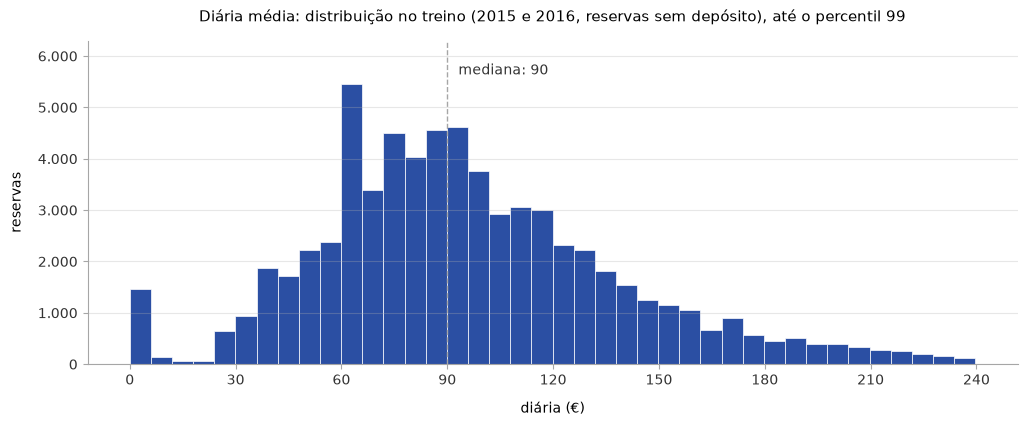

In [5]:
histograma('adr', 'Diária média', 'diária (€)')

**Leitura.**

- **`adr` concentra-se entre 66 e 120** (p25 e p75), com mediana de 90, percentil 99 de 240 e máximo de 508. 2,1% das reservas têm diária zero, que aparece como pico à esquerda no gráfico.

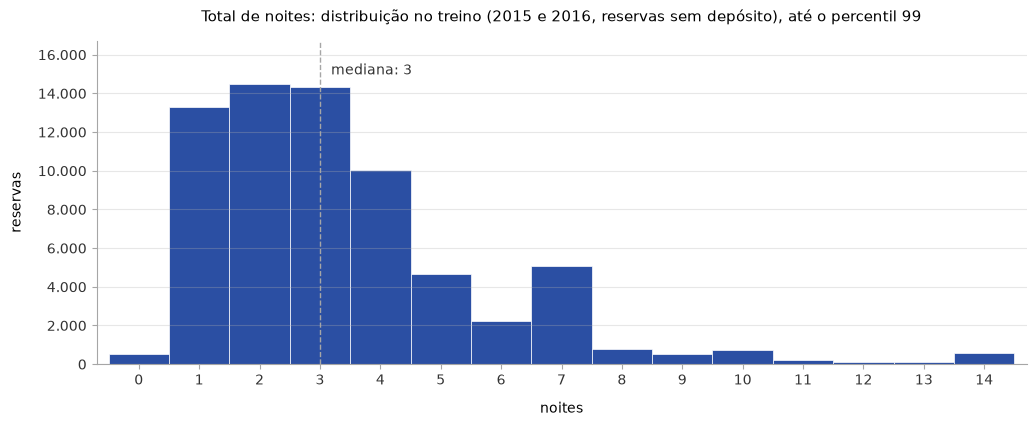

In [6]:
histograma('noites', 'Total de noites', 'noites')

**Leitura.**

- **`noites`: metade das reservas fica de 2 a 4 noites** (p25 e p75), com mediana de 3 e percentil 99 de 14. O pico em 7 é a semana fechada. Faixas de 1, 2–3, 4–7 e mais de 7 noites acompanham esse desenho.

### 2.2 Categóricas

In [7]:
categoricas = ['hotel', 'market_segment', 'distribution_channel', 'customer_type', 'meal',
               'reserved_room_type', 'is_repeated_guest']

frequencias = pd.concat({
    c: treino[c].value_counts().rename('reservas').to_frame().assign(pct=lambda t: t['reservas'] / t['reservas'].sum())
    for c in categoricas
})
frequencias.index.names = ['variavel', 'nivel']
frequencias['abaixo_de_1pct'] = frequencias['pct'] < 0.01
frequencias.round(4)

reservas     pct  abaixo_de_1pct
variavel             nivel                                            
hotel                City Hotel          42651  0.6273           False
                     Resort Hotel        25339  0.3727           False
market_segment       Online TA           33735  0.4962           False
                     Offline TA/TO       14666  0.2157           False
                     Direct               7942  0.1168           False
                     Groups               7424  0.1092           False
                     Corporate            3575  0.0526           False
                     Complementary         521  0.0077            True
                     Aviation              127  0.0019            True
distribution_channel TA/TO               54270  0.7982           False
                     Direct               9174  0.1349           False
                     Corporate            4440  0.0653           False
                     GDS                   105  0.0015            True
                     Undefined               1  0.0000            True
customer_type        Transient           46945  0.6905           False
                     Transient-Party     17831  0.2623           False
                     Contract             2866  0.0422           False
                     Group                 348  0.0051            True
meal                 BB                  53147  0.7817           False
                     HB                   8382  0.1233           False
                     SC                   5408  0.0795           False
                     Undefined             644  0.0095            True
                     FB                    409  0.0060            True
reserved_room_type   A                   48026  0.7064           False
                     D                   11427  0.1681           False
                     E                    3744  0.0551           False
                     F                    1794  0.0264           False
                     G                    1256  0.0185           False
                     B                     900  0.0132           False
                     C                     450  0.0066            True
                     H                     387  0.0057            True
                     L                       6  0.0001            True
is_repeated_guest    0                   65673  0.9659           False
                     1                    2317  0.0341           False

**Leitura.**

- **Categorias abaixo de 1% do treino:**
  - `market_segment`: Complementary (0,8%) e Aviation (0,2%). Juntam em "Outros";
  - `customer_type`: Group (348 reservas, 0,5%). Precisa juntar com outra categoria; a bivariada mostra com qual ela se parece;
  - `meal`: Undefined (644, 0,95%) e FB (409, 0,6%). Undefined fica separado ou junta com SC (notebook 01, seção 4.3); FB pode juntar com HB em "com pensão";
  - `reserved_room_type`: C, H e L (L tem 6 reservas). A variável tende a sair: o código do quarto não significa nada para o público;
  - `distribution_channel`: GDS (0,15%) e uma reserva Undefined. A variável tende a sair por repetir o segmento.
- **Referências naturais (a categoria mais frequente):** City Hotel (62,7%), Online TA (49,6%), Transient (69,1%), BB (78,2%).
- **`is_repeated_guest`:** 3,4% de hóspedes que voltam. Pequeno, mas são 2.317 reservas: dá para estimar.

In [8]:
# meses: volume por mês de chegada no treino (2015 só tem julho a dezembro)
meses = ['January', 'February', 'March', 'April', 'May', 'June',
         'July', 'August', 'September', 'October', 'November', 'December']
pd.crosstab(pd.Categorical(treino['arrival_date_month'], meses), treino['arrival_date_year'], margins=True)

arrival_date_year,2015,2016,All
row_0,,,
January,0,2050,2050
February,0,3382,3382
March,0,4229,4229
April,0,4481,4481
May,0,4745,4745
June,0,4316,4316
July,2544,4282,6826
August,3299,4792,8091
September,3905,4636,8541


**Leitura.**

- **O treino não pesa os meses por igual.** 2015 só tem julho a dezembro, então esses meses aparecem em dois anos e janeiro a junho, só em 2016. O efeito de janeiro a junho é estimado com um ano só.

### 2.3 Treino × teste

In [9]:
# a distribuição das candidatas muda em 2017? (o teste só tem janeiro a agosto)
comparacao_num = pd.DataFrame({
    'mediana_treino': treino[['lead_time', 'adr', 'noites']].median(),
    'mediana_teste': teste[['lead_time', 'adr', 'noites']].median(),
})
display(comparacao_num)

# mesmos meses (janeiro a agosto) para tirar o efeito da época do ano na diária e na antecedência
treino_jan_ago = treino[treino['arrival_date_month'].isin(jan_a_ago) & (treino['arrival_date_year'] == 2016)]
display(pd.DataFrame({
    'mediana_2016_jan_ago': treino_jan_ago[['lead_time', 'adr', 'noites']].median(),
    'mediana_2017_jan_ago': teste[['lead_time', 'adr', 'noites']].median(),
}))

,mediana_treino,mediana_teste
lead_time,50.0,73.0
adr,90.0,108.0
noites,3.0,3.0


,mediana_2016_jan_ago,mediana_2017_jan_ago
lead_time,54.0,73.0
adr,94.5,108.0
noites,3.0,3.0


**Leitura.**

- **2017 reserva com mais antecedência e paga mais caro.** Nos mesmos meses (janeiro a agosto), a antecedência mediana sobe de 54 para 73 dias, e a diária mediana, de 94,5 para 108. O total de noites não muda (3).

In [10]:
composicao = pd.concat({
    c: pd.DataFrame({'treino': treino[c].value_counts(normalize=True),
                     'teste': teste[c].value_counts(normalize=True)})
    for c in ['hotel', 'market_segment', 'customer_type']
}).fillna(0)
composicao['diferenca_pp'] = (composicao['teste'] - composicao['treino']) * 100
composicao.round(4)

treino   teste  diferenca_pp
hotel          City Hotel       0.6273  0.6477        2.0414
               Resort Hotel     0.3727  0.3523       -2.0414
market_segment Aviation         0.0019  0.0030        0.1094
               Complementary    0.0077  0.0057       -0.1986
               Corporate        0.0526  0.0375       -1.5039
               Direct           0.1168  0.1265        0.9718
               Groups           0.1092  0.0840       -2.5169
               Offline TA/TO    0.2157  0.1236       -9.2141
               Online TA        0.4962  0.6197       12.3525
customer_type  Transient        0.6905  0.8118       12.1301
               Transient-Party  0.2623  0.1642       -9.8106
               Contract         0.0422  0.0181       -2.4054
               Group            0.0051  0.0060        0.0860

**Leitura.**

- **O mix muda bastante:**
  - a agência online passa de 49,6% para 62,0% das reservas (+12,4 pontos), e a operadora tradicional cai 9,2 pontos;
  - o cliente avulso (Transient) passa de 69,0% para 81,2% (+12,1 pontos), e o avulso ligado a outra reserva (Transient-Party) cai 9,8 pontos.
- **O que isso muda:**
  - se a bivariada mostrar que a agência online e a antecedência longa cancelam mais, parte da alta de 2017 vem da composição. Essa parte o modelo capta, porque as variáveis estão nele; o resto aparece na calibração;
  - a diária sobe em 2017 também por preço. Se `adr` entrar como número, a mesma diária quer dizer coisas diferentes em cada ano. A conferir na bivariada se a relação entre a diária e o cancelamento é a mesma no treino e no teste.

## 3. Bivariada

**Pergunta:** como cada candidata se relaciona com o cancelamento, e em que forma ela entra no modelo?

Tudo no **treino** (2015 e 2016, no escopo). O teste só aparece quando a pergunta é se a relação se mantém em 2017.

### 3.1 Numéricas: número, faixas ou binária?

Na regressão logística, uma variável numérica tem efeito de reta no logito. O gráfico abaixo mostra o logito empírico de cada faixa contra o valor típico da faixa (a mediana): se os pontos caem numa reta, a variável entra como número; se não, vira faixas ou binária. Contínuas são cortadas em decis; contagens, por valor.

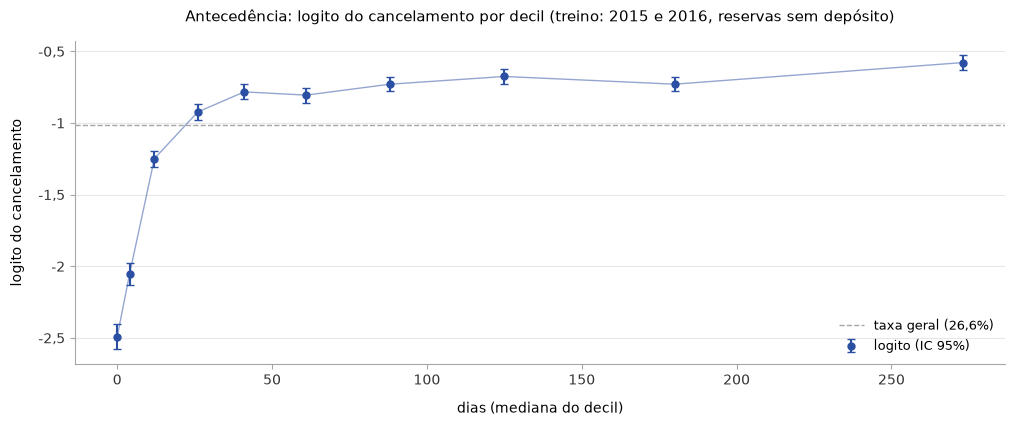

,decil,n,taxa,logito,mediana
lead_time,,,,,
"(-0.001, 1.0]",1,6907,0.0764,-2.4908,0.0
"(1.0, 7.0]",2,6857,0.1138,-2.0524,4.0
"(7.0, 18.0]",3,7086,0.2228,-1.2490,12.0
"(18.0, 33.0]",4,6512,0.2842,-0.9233,26.0
"(33.0, 50.0]",5,6670,0.3136,-0.7830,41.0
"(50.0, 73.0]",6,6797,0.3088,-0.8055,61.0
"(73.0, 104.0]",7,6874,0.3253,-0.7295,88.0
"(104.0, 150.0]",8,6784,0.3373,-0.6754,125.0
"(150.0, 215.0]",9,6753,0.3253,-0.7292,180.0


In [11]:
taxa_treino = treino['is_canceled'].mean()
colunas = ['decil', 'n', 'taxa', 'logito', 'mediana']

def logito_decis(coluna, titulo, rotulo):
    tabela = logito_por_faixa(treino, coluna)
    fig, ax = plt.subplots(figsize=(12, 4.2))
    grafico_logito(tabela, titulo=titulo, rotulo_x=rotulo, taxa_geral=taxa_treino, ax=ax)
    plt.show()
    return tabela[colunas].round(4).assign(mediana=lambda t: t['mediana'].round(1))   # mediana em dias ou euros

logito_decis('lead_time', 'Antecedência: logito do cancelamento por decil (treino: 2015 e 2016, reservas sem depósito)',
             'dias (mediana do decil)')

**Leitura.**

- **A antecedência não é linear no logito.** O cancelamento sobe rápido até um mês, de 7,6% (no mesmo dia ou no seguinte) para 28,4% (19 a 33 dias), e depois quase para: entre 30,9% e 35,9% de 34 a 737 dias. Uma reta não cobre os dois trechos. **Entra em faixas.**

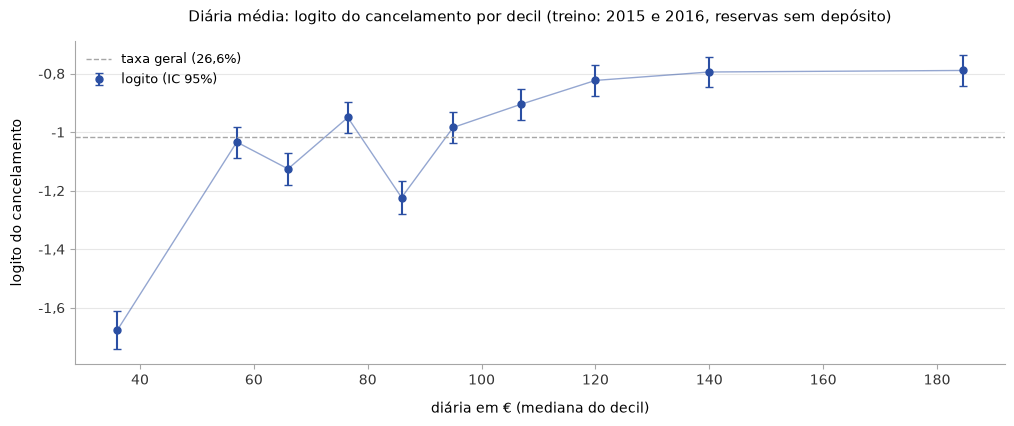

,decil,n,taxa,logito,mediana
adr,,,,,
"(-0.001, 47.0]",1,6822,0.1574,-1.6771,36.0
"(47.0, 62.0]",2,7096,0.2623,-1.0341,57.0
"(62.0, 72.0]",3,6680,0.2449,-1.1257,66.0
"(72.0, 80.75]",4,6940,0.2788,-0.9502,76.5
"(80.75, 90.0]",5,6776,0.2273,-1.2235,85.9
"(90.0, 100.0]",6,6724,0.2720,-0.9843,95.0
"(100.0, 113.0]",7,6557,0.2881,-0.9045,107.0
"(113.0, 129.0]",8,6807,0.3050,-0.8236,120.0
"(129.0, 156.6]",9,6811,0.3111,-0.7948,140.0


,n,taxa,ic_inf,ic_sup
faixa_adr,,,,
zero,1412,0.1041,0.0892,0.1211
até 47,5410,0.1713,0.1615,0.1816
acima de 47,61168,0.2779,0.2744,0.2815


In [12]:
display(logito_decis('adr', 'Diária média: logito do cancelamento por decil (treino: 2015 e 2016, reservas sem depósito)',
                     'diária em € (mediana do decil)'))

# o primeiro decil da diária inclui as diárias zero (notebook 01, seção 4.3)
taxa_por_nivel(treino.assign(faixa_adr=pd.cut(treino['adr'], [-1, 0, 47, np.inf], labels=['zero', 'até 47', 'acima de 47'])),
               'faixa_adr')[['n', 'taxa', 'ic_inf', 'ic_sup']].round(4)

**Leitura.**

- **A diária também não é linear.** O primeiro decil (até 47) cancela 15,7%, puxado pelas diárias zero (10,4%). Entre 47 e 100, a taxa oscila de 22,7% a 27,9%, sem escada; acima de 113, fica perto de 31%. **Vira faixas.** Os cortes ficam para depois de controlar hotel e temporada: a diária muda com os dois, e parte desse desenho pode vir deles.

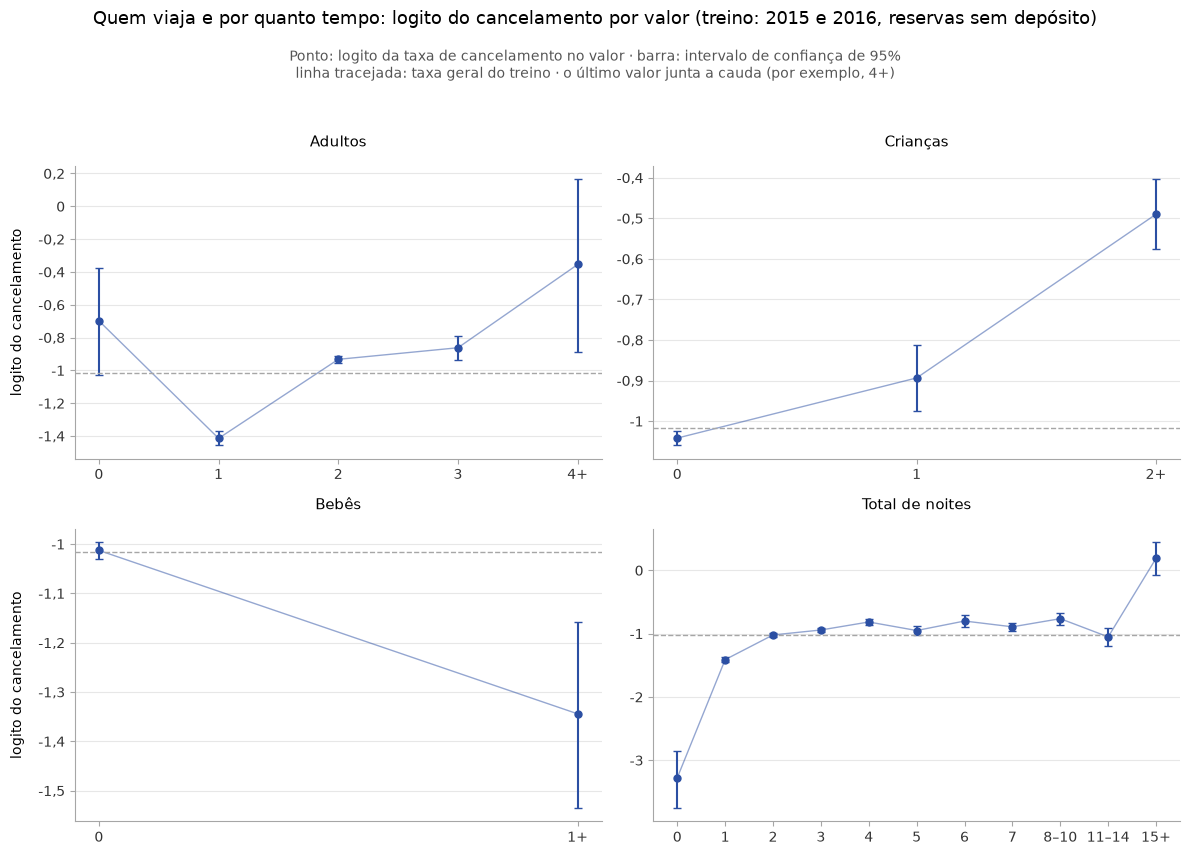

n    taxa  ic_inf  ic_sup
adults   0        160  0.3312  0.2630  0.4074
         1      13720  0.1956  0.1890  0.2023
         2      50507  0.2824  0.2785  0.2863
         3       3547  0.2969  0.2821  0.3121
         4+        56  0.4107  0.2917  0.5412
children 0      62954  0.2608  0.2574  0.2642
         1       2859  0.2903  0.2740  0.3072
         2+      2177  0.3799  0.3597  0.4005
babies   0      67331  0.2664  0.2631  0.2698
         1+       659  0.2064  0.1772  0.2389
noites   0        535  0.0355  0.0229  0.0548
         1      13318  0.1961  0.1895  0.2030
         2      14477  0.2649  0.2578  0.2722
         3      14350  0.2804  0.2731  0.2878
         4      10025  0.3066  0.2977  0.3157
         5       4657  0.2787  0.2660  0.2918
         6       2250  0.3098  0.2910  0.3292
         7       5055  0.2906  0.2782  0.3033
         8–10    2036  0.3178  0.2979  0.3383
         11–14   1055  0.2588  0.2332  0.2860
         15+      232  0.5474  0.4831  0.6102

In [13]:
# contagens: o último nível junta a cauda (por exemplo, 4+ = 4 ou mais adultos)
grupos = {
    'Quem viaja e por quanto tempo': [
        ('adults', [-1, 0, 1, 2, 3, np.inf], ['0', '1', '2', '3', '4+'], 'Adultos'),
        ('children', [-1, 0, 1, np.inf], ['0', '1', '2+'], 'Crianças'),
        ('babies', [-1, 0, np.inf], ['0', '1+'], 'Bebês'),
        ('noites', [-1, 0, 1, 2, 3, 4, 5, 6, 7, 10, 14, np.inf],
         ['0', '1', '2', '3', '4', '5', '6', '7', '8–10', '11–14', '15+'], 'Total de noites'),
    ],
    'Histórico do cliente e pedidos': [
        ('total_of_special_requests', [-1, 0, 1, 2, np.inf], ['0', '1', '2', '3+'], 'Pedidos especiais'),
        ('previous_cancellations', [-1, 0, 1, np.inf], ['0', '1', '2+'], 'Cancelamentos anteriores'),
        ('previous_bookings_not_canceled', [-1, 0, 1, 2, np.inf], ['0', '1', '2', '3+'], 'Reservas anteriores mantidas'),
        ('days_in_waiting_list', [-1, 0, np.inf], ['0', '1+'], 'Dias em lista de espera'),
    ],
}

def figura_contagens(tema):
    contagens = grupos[tema]
    tabelas = {}
    fig, eixos = plt.subplots(2, 2, figsize=(12, 8.5))
    for ax, (coluna, limites, rotulos, titulo) in zip(eixos.flat, contagens):
        tabelas[coluna] = logito_por_faixa(treino, coluna, limites=limites)
        tabelas[coluna].index = rotulos
        # níveis igualmente espaçados no eixo; a cauda fica no último
        grafico_logito(tabelas[coluna], titulo=titulo, taxa_geral=taxa_treino, posicao=range(len(rotulos)), ax=ax)
        ax.set_xticks(range(len(rotulos)), rotulos)
        ax.get_legend().remove()
        ax.set_ylabel('')
    for ax in eixos[:, 0]:
        ax.set_ylabel('logito do cancelamento')
    fig.suptitle(f'{tema}: logito do cancelamento por valor (treino: 2015 e 2016, reservas sem depósito)',
                 fontsize=13, y=1.0)
    fig.text(0.5, 0.955, 'Ponto: logito da taxa de cancelamento no valor · barra: intervalo de confiança de 95%\n'
             'linha tracejada: taxa geral do treino · o último valor junta a cauda (por exemplo, 4+)',
             ha='center', va='top', fontsize=10, color='#555555')
    plt.tight_layout(rect=(0, 0, 1, 0.91))
    plt.show()
    return pd.concat({c: t[['n', 'taxa', 'ic_inf', 'ic_sup']] for c, t in tabelas.items()}).round(4)


figura_contagens('Quem viaja e por quanto tempo')

**Leitura.**

- **`adults`: o nível 1 se separa.** Um adulto cancela 19,6%; dois, 28,2%; três, 29,7%, com intervalos que quase se tocam. Os extremos têm poucas reservas e intervalos largos: 0 adulto (160 reservas, 33,1%) e 4 ou mais (56, 41,1%). **Binária: sozinho (1 adulto) × acompanhado** (os demais, incluindo os 160 sem adulto).
- **`children`: escada.** Sem criança, 26,1%; uma, 29,0%; duas ou mais, 38,0%. **Binária, com criança × sem**, ou três níveis se o modelo mostrar que a diferença entre uma e duas compensa.
- **`babies` vai no sentido oposto.** Com bebê, 20,6% (IC de 17,7% a 23,9%), contra 26,6% sem. Juntar com `children` misturaria efeitos contrários. São 659 reservas (1% do treino). **Sai.**
- **`noites`: zero noites é outro comportamento.** 3,6% de cancelamento (535 reservas), contra 19,6% com uma noite; de 2 a 14 noites, a taxa fica entre 25,9% e 31,8%. 15 noites ou mais cancelam 54,7%, mas são só 232. **Entra em faixas** (abaixo).

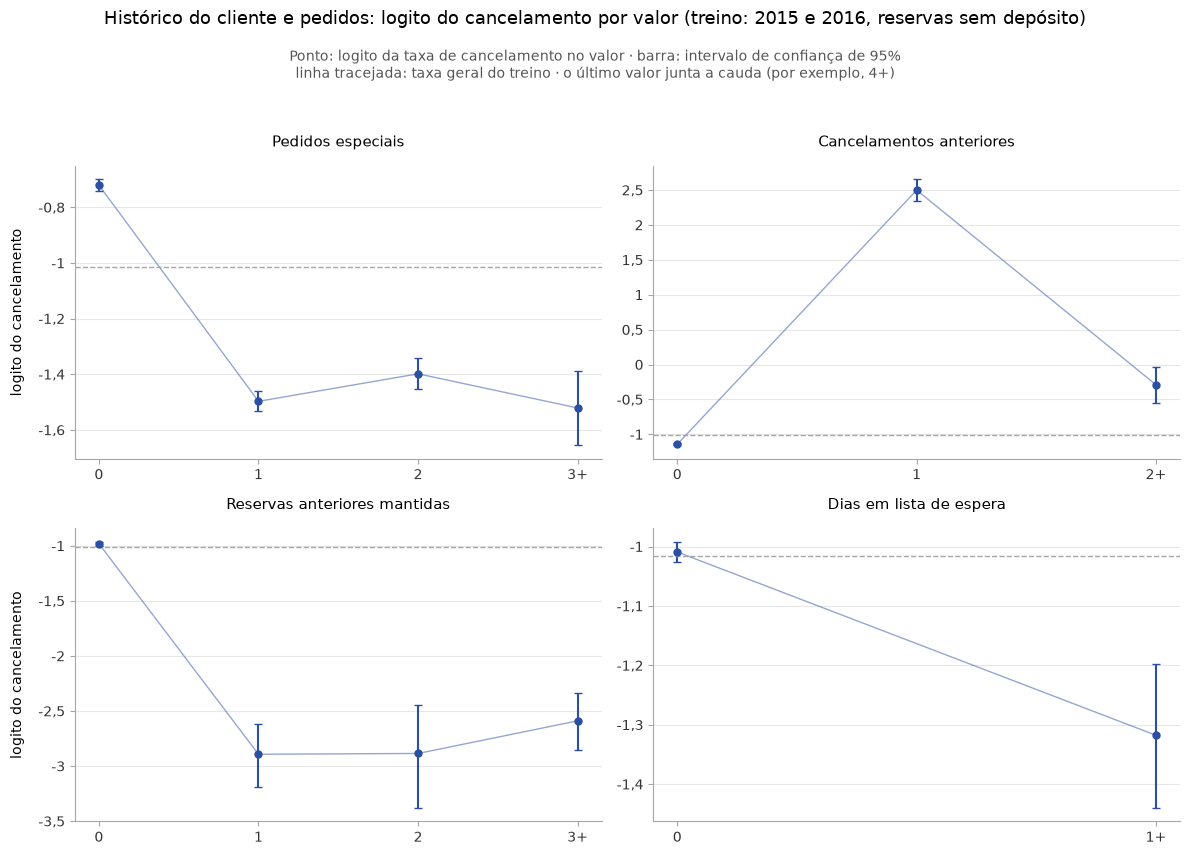

n    taxa  ic_inf  ic_sup
total_of_special_requests      0   38295  0.3273  0.3226  0.3320
                               1   20433  0.1828  0.1776  0.1882
                               2    7793  0.1980  0.1893  0.2070
                               3+   1469  0.1790  0.1603  0.1995
previous_cancellations         0   65434  0.2419  0.2386  0.2452
                               1    2322  0.9242  0.9127  0.9343
                               2+    234  0.4274  0.3656  0.4914
previous_bookings_not_canceled 0   65819  0.2727  0.2693  0.2761
                               1     942  0.0520  0.0396  0.0681
                               2     349  0.0516  0.0329  0.0800
                               3+    880  0.0693  0.0543  0.0880
days_in_waiting_list           0   66426  0.2671  0.2638  0.2705
                               1+   1564  0.2110  0.1915  0.2319

In [14]:
figura_contagens('Histórico do cliente e pedidos')

**Leitura.**

- **`total_of_special_requests`: o que importa é fazer algum pedido.** Sem pedido, 32,7%; com 1, 2 ou 3 ou mais, entre 17,9% e 19,8%. **Binária: fez pedido × não fez**, se o momento do score permitir.
- **`previous_bookings_not_canceled`: o mesmo desenho.** Nunca veio, 27,3%; já veio uma ou mais vezes, entre 5,2% e 6,9%. **Binária: já veio × nunca veio.**
- **`days_in_waiting_list`:** quem esperou cancela 21,1%, contra 26,7%. São 2,3% das reservas: pouco ganho para uma variável a mais. **Sai.**
- **`previous_cancellations` não segue escada nenhuma:** uma vez, 92,4%; duas ou mais, 42,7%. Investigado abaixo.

In [15]:
# cancelamentos anteriores: quem são as reservas com exatamente 1?
treino_pc = treino.assign(cancelou_antes=treino['previous_cancellations'].clip(upper=2))
display(treino_pc.groupby('cancelou_antes').agg(
    reservas=('is_canceled', 'size'),
    taxa=('is_canceled', 'mean'),
    pct_2015=('arrival_date_year', lambda s: (s == 2015).mean()),
    antecedencia_mediana=('lead_time', 'median'),
    pct_com_gemea=('tem_gemea', 'mean'),
    pct_hospede_repetido=('is_repeated_guest', 'mean'),
).rename(index={2: '2 ou mais'}))

,reservas,taxa,pct_2015,antecedencia_mediana,pct_com_gemea,pct_hospede_repetido
cancelou_antes,,,,,,
0,65434,0.241908,0.250206,49.0,0.251887,0.025904
1,2322,0.924203,0.798450,199.0,0.651163,0.197244
2 ou mais,234,0.427350,0.282051,8.0,0.252137,0.700855


**Leitura.**

- **As reservas com exatamente um cancelamento anterior não são clientes que costumam cancelar.** 79,8% são de 2015 (contra 25,0% das reservas sem cancelamento anterior), têm antecedência mediana de 199 dias e 65,1% têm gêmea. É o perfil dos blocos de quartos do notebook 01, seção 4.2, concentrados no início da base.
- **Explicação provável:** em 2015, a contagem parece registrar os outros quartos do mesmo bloco cancelado, e não o histórico do cliente. Não dá para confirmar sem o sistema do hotel.

In [16]:
# a relação se mantém em 2017?
pd.DataFrame({
    'taxa_treino': treino.groupby(treino['previous_cancellations'].clip(upper=2))['is_canceled'].mean(),
    'taxa_teste': teste.groupby(teste['previous_cancellations'].clip(upper=2))['is_canceled'].mean(),
    'n_teste': teste.groupby(teste['previous_cancellations'].clip(upper=2)).size(),
}).rename(index={2: '2 ou mais'}).round(4)

,taxa_treino,taxa_teste,n_teste
previous_cancellations,,,
0,0.2419,0.3189,36189
1,0.9242,0.1753,194
2 ou mais,0.4274,0.1687,83


**Leitura.**

- **Em 2017, a relação se inverte.** No teste, quem tem um cancelamento anterior cancela 17,5%, contra 31,9% de quem não tem. No treino eram 92,4%. Uma variável que muda de sentido entre os períodos ensinaria ao modelo uma regra que não vale no futuro.
- **Proposta: sai.** O histórico do cliente continua representado por "já veio × nunca veio".

In [17]:
# faixas propostas para a antecedência e o total de noites
faixas_lead = pd.cut(treino['lead_time'], [-1, 7, 30, 90, 180, np.inf],
                     labels=['até 7', '8–30', '31–90', '91–180', 'mais de 180'])
faixas_noites = pd.cut(treino['noites'], [-1, 1, 3, 7, np.inf], labels=['até 1', '2–3', '4–7', 'mais de 7'])

taxa_por_nivel(treino.assign(faixa_lead=faixas_lead), 'faixa_lead')[['n', 'pct_base', 'taxa', 'ic_inf', 'ic_sup']].round(4)

,n,pct_base,taxa,ic_inf,ic_sup
faixa_lead,,,,,
até 7,13764,0.2024,0.0950,0.0902,0.1000
8–30,12261,0.1803,0.2483,0.2408,0.2561
31–90,18721,0.2753,0.3078,0.3012,0.3144
91–180,13177,0.1938,0.3338,0.3258,0.3419
mais de 180,10067,0.1481,0.3538,0.3445,0.3632


**Leitura.**

- **Antecedência em cinco faixas:** até 7 dias, 9,5%; 8–30, 24,8%; 31–90, 30,8%; 91–180, 33,4%; mais de 180, 35,4%. As faixas acompanham a curva, e os intervalos de faixas vizinhas não se sobrepõem. A primeira junta o mesmo dia (7,6%) e de 2 a 7 dias (11,4%), que ficam próximos. **Proposta: estas faixas, com 31–90 como referência** (a maior, 27,5% do treino).

In [18]:
taxa_por_nivel(treino.assign(faixa_noites=faixas_noites), 'faixa_noites')[['n', 'pct_base', 'taxa', 'ic_inf', 'ic_sup']].round(4)

,n,pct_base,taxa,ic_inf,ic_sup
faixa_noites,,,,,
até 1,13853,0.2038,0.1899,0.1835,0.1965
2–3,28827,0.4240,0.2726,0.2675,0.2778
4–7,21987,0.3234,0.2974,0.2914,0.3034
mais de 7,3323,0.0489,0.3151,0.2995,0.3311


**Leitura.**

- **Noites em quatro faixas:** até 1, 19,0%; 2–3, 27,3%; 4–7, 29,7%; mais de 7, 31,5%. Juntar as 535 reservas de zero noites com as de uma noite quase não mexe na faixa (de 19,6% para 19,0%) e evita uma categoria de 0,8% do treino. As duas últimas faixas têm intervalos que se tocam (29,1%–30,3% e 30,0%–33,1%): se o modelo não as separar, juntam em "4 ou mais". **Referência: 2–3** (42,4% do treino).

### 3.2 Categóricas: força e agrupamentos

O V de Cramér ordena as candidatas pela força da associação com o cancelamento (de 0 a 1). Com muitos níveis, o V tende a sair maior só por isso: a comparação vale melhor entre variáveis com poucos níveis.

In [19]:
treino = treino.assign(
    segmento=treino['market_segment'].replace({'Complementary': 'Outros', 'Aviation': 'Outros', 'Undefined': 'Outros'}),
    tem_agencia=treino['agent'].notna(),
    tem_empresa=treino['company'].notna(),
)

candidatas = ['hotel', 'segmento', 'distribution_channel', 'customer_type', 'meal', 'reserved_room_type',
              'is_repeated_guest', 'arrival_date_month', 'tem_agencia', 'tem_empresa', 'agent', 'company']
pd.DataFrame({
    'niveis': [treino[c].nunique() for c in candidatas],
    'V_cramer': [v_cramer(treino, c) for c in candidatas],
}, index=candidatas).sort_values('V_cramer', ascending=False).round(4)

,niveis,V_cramer
company,289,0.4035
agent,275,0.2830
segmento,6,0.1949
distribution_channel,5,0.1287
tem_agencia,2,0.1132
tem_empresa,2,0.0875
arrival_date_month,12,0.0811
meal,5,0.0717
hotel,2,0.0705
customer_type,4,0.0478


**Leitura.**

- **Entre as variáveis de poucos níveis, o segmento é a mais forte** (V de 0,195). Depois vêm o canal (0,129), `tem_agencia` (0,113), `tem_empresa` (0,087), o mês (0,081), `meal` (0,072) e o hotel (0,070). Tipo de cliente, tipo de quarto e hóspede que volta ficam abaixo de 0,05.
- **`agent` e `company` têm V alto (0,283 e 0,404), mas com 275 e 289 códigos.** Boa parte disso vem do número de níveis. Investigadas abaixo.

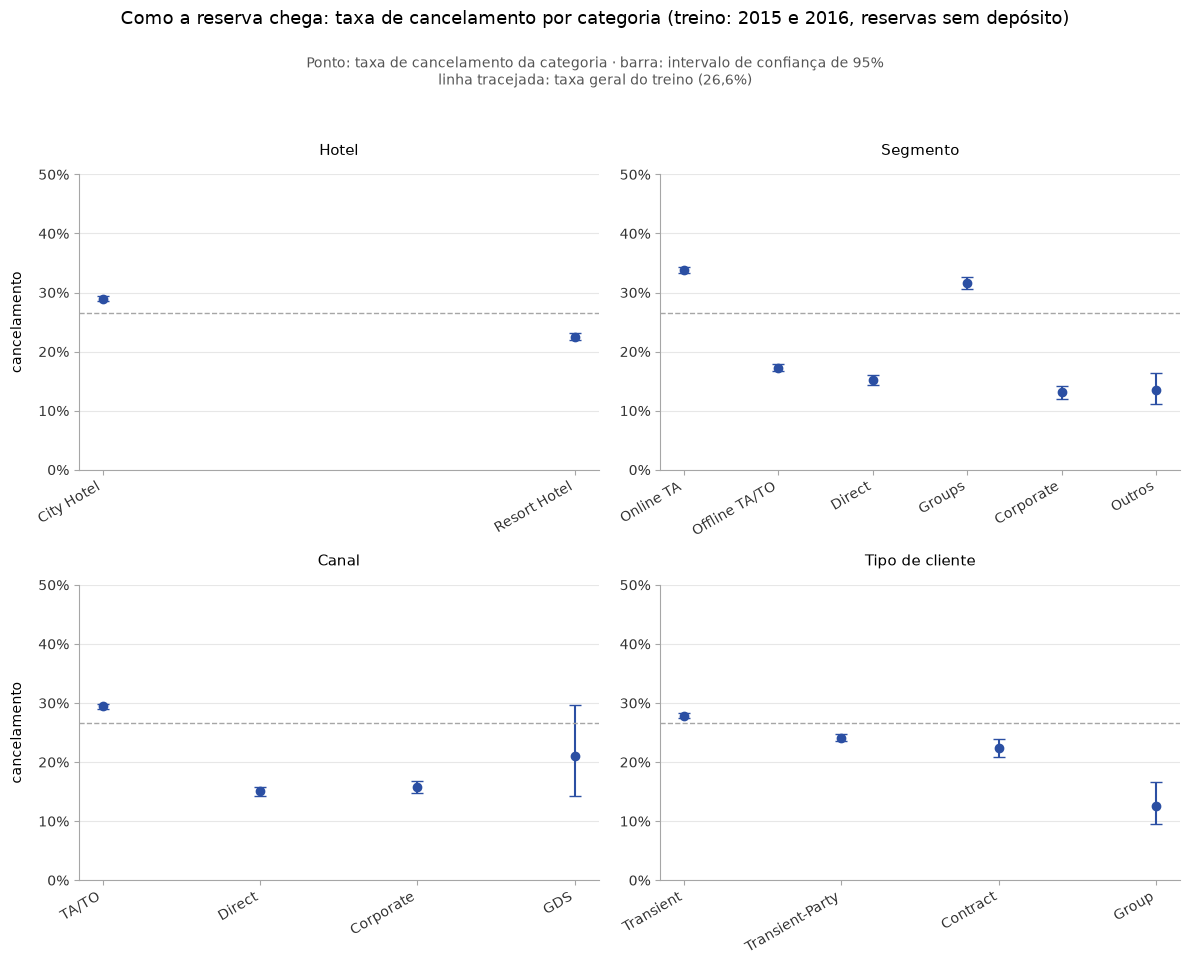

n    taxa  ic_inf  ic_sup
hotel                City Hotel       42651  0.2898  0.2856  0.2942
                     Resort Hotel     25339  0.2255  0.2204  0.2306
segmento             Corporate         3575  0.1309  0.1202  0.1424
                     Direct            7942  0.1520  0.1442  0.1600
                     Groups            7424  0.3159  0.3054  0.3265
                     Offline TA/TO    14666  0.1729  0.1669  0.1791
                     Online TA        33735  0.3388  0.3338  0.3439
                     Outros             648  0.1358  0.1116  0.1643
distribution_channel Corporate         4440  0.1572  0.1468  0.1682
                     Direct            9174  0.1502  0.1430  0.1577
                     GDS                105  0.2095  0.1426  0.2969
                     TA/TO            54270  0.2944  0.2906  0.2982
                     Undefined            1  0.0000  0.0000  0.7935
customer_type        Contract          2866  0.2237  0.2088  0.2393
                     Group              348  0.1264  0.0956  0.1655
                     Transient        46945  0.2787  0.2747  0.2828
                     Transient-Party  17831  0.2414  0.2352  0.2478

In [20]:
# níveis com menos de 30 reservas ficam só na tabela (intervalo largo demais para o gráfico)
temas = {
    'Como a reserva chega': [('hotel', 'Hotel'), ('segmento', 'Segmento'),
                             ('distribution_channel', 'Canal'), ('customer_type', 'Tipo de cliente')],
    'O que foi reservado': [('meal', 'Regime de refeição'), ('reserved_room_type', 'Tipo de quarto reservado')],
}
legenda = (f'Ponto: taxa de cancelamento da categoria · barra: intervalo de confiança de 95%\n'
           f'linha tracejada: taxa geral do treino ({taxa_treino:.1%})'.replace('.', ','))

def figura_categorias(tema, com_tabela):
    variaveis = temas[tema]
    linhas = (len(variaveis) + 1) // 2
    fig, eixos = plt.subplots(linhas, 2, figsize=(12, 4.4 * linhas + 0.8), squeeze=False)
    for ax, (coluna, titulo) in zip(eixos.flat, variaveis):
        tabela = taxa_por_nivel(treino, coluna).sort_values('n', ascending=False).query('n >= 30')
        grafico_taxa_por_nivel(tabela, taxa_geral=taxa_treino, titulo=titulo, ax=ax)
        ax.set_ylim(0, 0.5)   # mesma escala em todos, para comparar a força entre variáveis
        plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
        ax.get_legend().remove()
        ax.set_ylabel('')
    for ax in eixos[:, 0]:
        ax.set_ylabel('cancelamento')
    topo = 1 - 0.85 / fig.get_figheight()   # espaço fixo para o título e a legenda
    fig.suptitle(f'{tema}: taxa de cancelamento por categoria (treino: 2015 e 2016, reservas sem depósito)',
                 fontsize=13, y=1.0)
    fig.text(0.5, 1 - 0.45 / fig.get_figheight(), legenda, ha='center', va='top', fontsize=10, color='#555555')
    plt.tight_layout(rect=(0, 0, 1, topo))
    plt.show()
    return pd.concat({c: taxa_por_nivel(treino, c)[['n', 'taxa', 'ic_inf', 'ic_sup']] for c in com_tabela}).round(4)


figura_categorias('Como a reserva chega', ['hotel', 'segmento', 'distribution_channel', 'customer_type'])

**Leitura.**

- **Segmento:** Agência online cancela 33,9% e grupos, 31,6%; operadora tradicional, 17,3%; direto, 15,2%; corporativo, 13,1%. **Entra, com a agência online como referência.**
- **Hotel:** urbano 29,0%, resort 22,5% (V de 0,070). **Entra**: é o primeiro corte do negócio.
- **O canal repete o segmento com menos detalhe** (V de 0,129). TA/TO (29,4%) mistura a agência online (33,9%) e a operadora tradicional (17,3%). **Sai**; a redundância é conferida na seção 4.
- **Tipo de cliente:** avulso 27,9%, avulso ligado a outra reserva 24,1%, contrato 22,4% e grupo 12,6% (V de 0,048). Fraco. O nível Group é investigado abaixo.

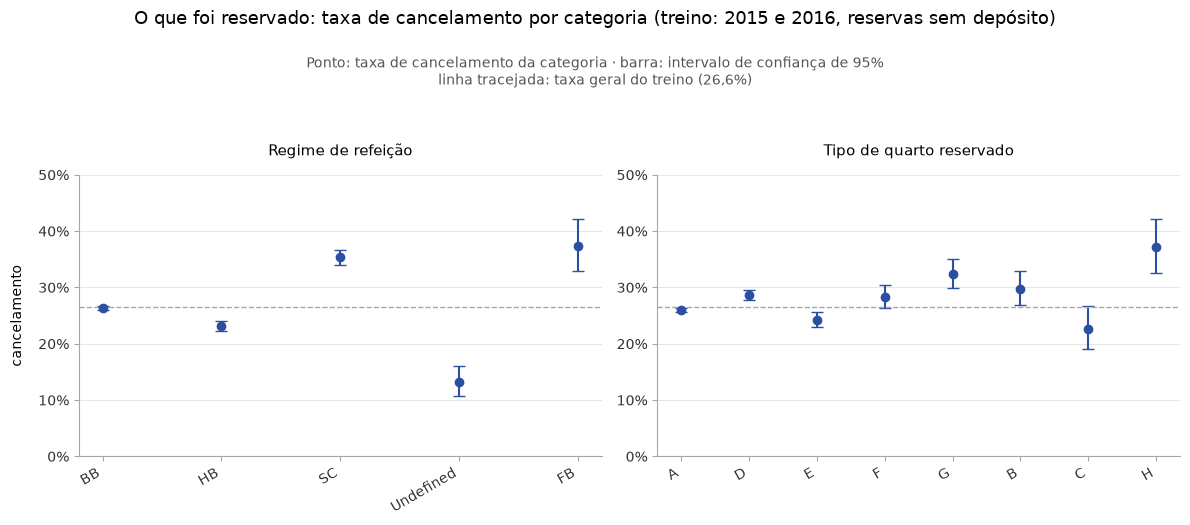

n    taxa  ic_inf  ic_sup
meal               BB         53147  0.2633  0.2595  0.2670
                   FB           409  0.3741  0.3286  0.4219
                   HB          8382  0.2309  0.2220  0.2400
                   SC          5408  0.3532  0.3406  0.3660
                   Undefined    644  0.1320  0.1080  0.1603
reserved_room_type A          48026  0.2594  0.2555  0.2634
                   B            900  0.2978  0.2688  0.3285
                   C            450  0.2267  0.1904  0.2676
                   D          11427  0.2866  0.2784  0.2950
                   E           3744  0.2428  0.2293  0.2568
                   F           1794  0.2832  0.2628  0.3045
                   G           1256  0.3240  0.2987  0.3504
                   H            387  0.3721  0.3254  0.4213
                   L              6  0.3333  0.0968  0.7000
is_repeated_guest  0          65673  0.2688  0.2654  0.2722
                   1           2317  0.1834  0.1682  0.1997

In [21]:
figura_categorias('O que foi reservado', ['meal', 'reserved_room_type', 'is_repeated_guest'])

**Leitura.**

- **Tipo de quarto:** taxas de 22,7% a 37,2%, sem ordem, e o código não significa nada para o público (V de 0,039). **Sai.**
- **Hóspede que volta:** 18,3% contra 26,9% (V de 0,035). Parecido com "já veio × nunca veio" (seção 3.1); a redundância é conferida na seção 4.
- **`meal`:** investigado abaixo.

In [22]:
# meal: Undefined e SC são a mesma coisa? Onde cada um aparece
pd.crosstab(treino['meal'], treino['hotel'], margins=True, margins_name='total')

hotel,City Hotel,Resort Hotel,total
meal,,,
BB,33626,19521,53147
FB,41,368,409
HB,3616,4766,8382
SC,5368,40,5408
Undefined,0,644,644
total,42651,25339,67990


**Leitura.**

- **Cada hotel registra "sem refeição" de um jeito.** Undefined só aparece no resort (644 reservas, nenhuma no urbano); SC aparece quase só no urbano (5.368, contra 40 no resort).

In [23]:
# taxa de cancelamento de cada regime, em cada hotel
taxa_por_nivel(treino, ['hotel', 'meal'])[['n', 'taxa', 'ic_inf', 'ic_sup']].round(4)

n    taxa  ic_inf  ic_sup
hotel        meal                                    
City Hotel   BB         33626  0.2858  0.2810  0.2906
             FB            41  0.8537  0.7156  0.9312
             HB          3616  0.2237  0.2104  0.2376
             SC          5368  0.3556  0.3429  0.3685
Resort Hotel BB         19521  0.2245  0.2187  0.2304
             FB           368  0.3207  0.2750  0.3700
             HB          4766  0.2363  0.2244  0.2485
             SC            40  0.0250  0.0044  0.1288
             Undefined    644  0.1320  0.1080  0.1603

**Leitura.**

- **E os dois vão em sentidos opostos.** No urbano, SC cancela 35,6%, contra 28,6% do café da manhã (BB). No resort, Undefined cancela 13,2%, contra 22,5% do BB. Juntar SC e Undefined em "sem refeição" mistura um efeito para cima com um para baixo.
- **Pensão completa (FB):** 85,4% no urbano, mas são só 41 reservas; 32,1% no resort (368). Meia pensão (HB) fica perto de 23% nos dois hotéis.
- **Proposta: `meal` vai para teste com quatro níveis**: BB (referência), com pensão (HB e FB), SC e Undefined. Undefined fica separado mesmo sendo pequeno (0,9% do treino), porque não se parece com nenhum outro nível. A variável é fraca (V de 0,072): se não melhorar o modelo, sai.

In [24]:
# customer_type = Group (348 reservas): de que segmentos vêm, e com quem se parece?
pd.crosstab(treino['customer_type'], treino['segmento'], normalize='index').round(2)

segmento,Corporate,Direct,Groups,Offline TA/TO,Online TA,Outros
customer_type,,,,,,
Contract,0.01,0.00,0.06,0.41,0.52,0.00
Group,0.04,0.23,0.01,0.38,0.33,0.01
Transient,0.05,0.15,0.01,0.14,0.63,0.01
Transient-Party,0.07,0.04,0.38,0.37,0.13,0.00


**Leitura.**

- **Group (348 reservas, 12,6% de cancelamento) não se parece com nenhum outro tipo de cliente.** O mais próximo é contrato (22,4%). Vem de operadoras (38%), agência online (33%) e reservas diretas (23%): não é o mesmo que o segmento Groups.
- **O avulso ligado a outra reserva (Transient-Party) é 38% do segmento Groups**: o tipo de cliente repete parte do segmento.
- **Sem proposta por ora: a seção 4 decide.** Group tem poucas reservas (348, 0,5% do treino) e não se parece com nenhum outro nível. As possibilidades:
  - **juntar com contrato:** a taxa mais próxima (22,4%), mas ainda 10 pontos acima, e os intervalos não se tocam;
  - **juntar com o avulso ligado a outra reserva:** o conceito mais próximo (reservas ligadas a outras), mas com taxa mais longe (24,1%);
  - **deixar separado**, como Undefined em `meal`: coerente com o critério de lá, mas o efeito sai instável com 348 reservas;
  - **tirar `customer_type` do modelo:** a variável é fraca (V de 0,048) e repete parte do segmento. Se a seção 4 mostrar que ela não acrescenta nada ao segmento, a questão do Group desaparece.

In [25]:
# mês de chegada: o padrão se repete nos dois anos do treino?
por_mes_ano = treino.pivot_table(index='arrival_date_month', columns='arrival_date_year',
                                 values='is_canceled', aggfunc=['mean', 'size']).reindex(meses)
por_mes_ano.round(4)

mean            size        
arrival_date_year     2015    2016    2015    2016
arrival_date_month                                
January                NaN  0.1751     NaN  2050.0
February               NaN  0.2466     NaN  3382.0
March                  NaN  0.2282     NaN  4229.0
April                  NaN  0.2600     NaN  4481.0
May                    NaN  0.2575     NaN  4745.0
June                   NaN  0.2604     NaN  4316.0
July                0.4045  0.2849  2544.0  4282.0
August              0.3074  0.3272  3299.0  4792.0
September           0.2279  0.2744  3905.0  4636.0
October             0.1701  0.3219  3868.0  5411.0
November            0.1775  0.2549  2248.0  3755.0
December            0.2014  0.3227  2428.0  3619.0

**Leitura.**

- **O padrão por mês não se repete nos dois anos.** Julho cancelou 40,4% em 2015 e 28,5% em 2016; outubro, 17,0% e 32,2%; dezembro, 20,1% e 32,3%. Com 12 meses como categorias, o modelo aprenderia oscilações de um ano só.
- **Só julho e agosto ficam acima nos dois anos:** 35,0% em 2015 e 30,7% em 2016. Os outros meses mudam de nível de um ano para o outro.

In [26]:
# três temporadas candidatas (jul–ago, abr–jun, set–mar), em cada ano do treino
temporada = treino['arrival_date_month'].map({'July': 'jul–ago', 'August': 'jul–ago',
                                              'April': 'abr–jun', 'May': 'abr–jun', 'June': 'abr–jun'}).fillna('set–mar')
taxa_por_nivel(treino.assign(temporada=temporada), ['temporada', 'arrival_date_year'])[['n', 'taxa', 'ic_inf', 'ic_sup']].round(4)

n    taxa  ic_inf  ic_sup
temporada arrival_date_year                               
abr–jun   2016               13542  0.2593  0.2520  0.2667
jul–ago   2015                5843  0.3496  0.3375  0.3620
          2016                9074  0.3073  0.2978  0.3168
set–mar   2015               12449  0.1957  0.1888  0.2027
          2016               27082  0.2694  0.2642  0.2748

**Leitura.**

- **Abril a junho não se separa de setembro a março.** Em 2016, o único ano com os dois períodos, cancelam 25,9% e 26,9%, com intervalos que se tocam. As três temporadas candidatas viram, na prática, duas.
- **Proposta: alta temporada (julho e agosto) × resto do ano.** A diferença de 2015 para 2016 em setembro a março (19,6% para 26,9%) é a mesma tendência de alta vista no notebook 01, seção 3, e não um efeito da época do ano.

In [27]:
# agência e empresa: o vazio diz algo além do segmento?
taxa_por_nivel(treino, ['segmento', 'tem_agencia'])[['n', 'taxa']].round(4)

n    taxa
segmento      tem_agencia               
Corporate     False         3023  0.1247
              True           552  0.1649
Direct        False         4201  0.1264
              True          3741  0.1807
Groups        False         1537  0.2297
              True          5887  0.3384
Offline TA/TO False          148  0.2568
              True         14518  0.1721
Online TA     False          227  0.0705
              True         33508  0.3407
Outros        False          566  0.1325
              True            82  0.1585

**Leitura.**

- **`tem_agencia` repete o segmento.** Na agência online e na operadora, quase todas as reservas têm agência; as sem agência são poucas (227 e 148). Onde há volume nos dois lados (direto, corporativo e grupos), ter agência soma de 4 a 11 pontos, mas o segmento já separa a maior parte. **Sai.**

In [28]:
taxa_por_nivel(treino, ['segmento', 'tem_empresa'])[['n', 'taxa']].round(4)

n    taxa
segmento      tem_empresa               
Corporate     False          649  0.1541
              True          2926  0.1258
Direct        False         7810  0.1528
              True           132  0.1061
Groups        False         6799  0.3405
              True           625  0.0480
Offline TA/TO False        14638  0.1731
              True            28  0.0714
Online TA     False        33666  0.3395
              True            69  0.0435
Outros        False          315  0.1206
              True           333  0.1502

**Leitura.**

- **`tem_empresa` separa dentro do segmento.** Nos grupos, a reserva paga por empresa cancela 4,8% (625 reservas), contra 34,0% sem empresa. No corporativo, a diferença é pequena (12,6% contra 15,4%). São 4.113 reservas com empresa (6,0% do treino). **Proposta: testar "paga por empresa" como binária.** A empresa é conhecida na reserva, e a leitura para o negócio é direta.

In [29]:
# as maiores agências: o código separa reservas de risco diferente?
maiores = treino['agent'].value_counts().head(8).index
print('Agências no treino:', treino['agent'].nunique(),
      f"| as 8 maiores somam {treino['agent'].isin(maiores).mean():.1%} das reservas")
(taxa_por_nivel(treino[treino['agent'].isin(maiores)], ['agent', 'segmento'])[['n', 'taxa']]
     .query('n >= 100').round(4))

Agências no treino: 275 | as 8 maiores somam 58.2% das reservas


,,n,taxa
agent,segmento,,
1.0,Groups,3074,0.3904
6.0,Offline TA/TO,1984,0.1381
7.0,Online TA,2123,0.1385
9.0,Online TA,18656,0.3862
14.0,Direct,1967,0.1952
28.0,Offline TA/TO,1124,0.0454
240.0,Online TA,8922,0.3575
250.0,Direct,1687,0.1642


**Leitura.**

- **O código da agência separa reservas do mesmo segmento.** Na agência online, a agência 9 cancela 38,6% e a 7, 13,8%; na operadora, a 6 cancela 13,8% e a 28, 4,5%. Mas são 275 códigos anônimos, e as 8 maiores somam 58,2% das reservas. **Sai do modelo:** dummies por código não se explicam para a diretoria. **Próximo passo para o negócio:** com o nome real das agências, a taxa por agência vira uma lista de parceiros a acompanhar.

### 3.3 Treino × teste: a relação se mantém em 2017?

A seção 2.3 mostrou que 2017 tem diárias mais altas e mais reservas da agência online e com antecedência longa. Duas perguntas ficaram abertas:

1. a diária se relaciona com o cancelamento do mesmo jeito nos dois períodos?
2. quanto da alta de 2017 (de 26,6% para 31,8%) vem da mudança no perfil das reservas, e quanto de um cancelamento maior dentro de cada perfil?

treino                         teste                        
                    n    taxa  ic_inf  ic_sup     n    taxa  ic_inf  ic_sup
decil_adr                                                                  
(-inf, 47.0]     6822  0.1574  0.1490  0.1663  2404  0.1809  0.1661  0.1968
(47.0, 62.0]     7096  0.2623  0.2522  0.2726  2113  0.2362  0.2185  0.2547
(62.0, 72.0]     6680  0.2449  0.2347  0.2554  2102  0.1855  0.1695  0.2027
(72.0, 80.75]    6940  0.2788  0.2684  0.2895  3057  0.2761  0.2605  0.2922
(80.75, 90.0]    6776  0.2273  0.2175  0.2374  3004  0.3236  0.3071  0.3405
(90.0, 100.0]    6724  0.2720  0.2615  0.2828  3356  0.2914  0.2763  0.3070
(100.0, 113.0]   6557  0.2881  0.2773  0.2992  3616  0.3186  0.3036  0.3340
(113.0, 129.0]   6807  0.3050  0.2942  0.3160  4507  0.3379  0.3243  0.3519
(129.0, 156.6]   6811  0.3111  0.3002  0.3222  5283  0.3825  0.3695  0.3957
(156.6, inf]     6777  0.3122  0.3013  0.3234  7024  0.3952  0.3838  0.4067

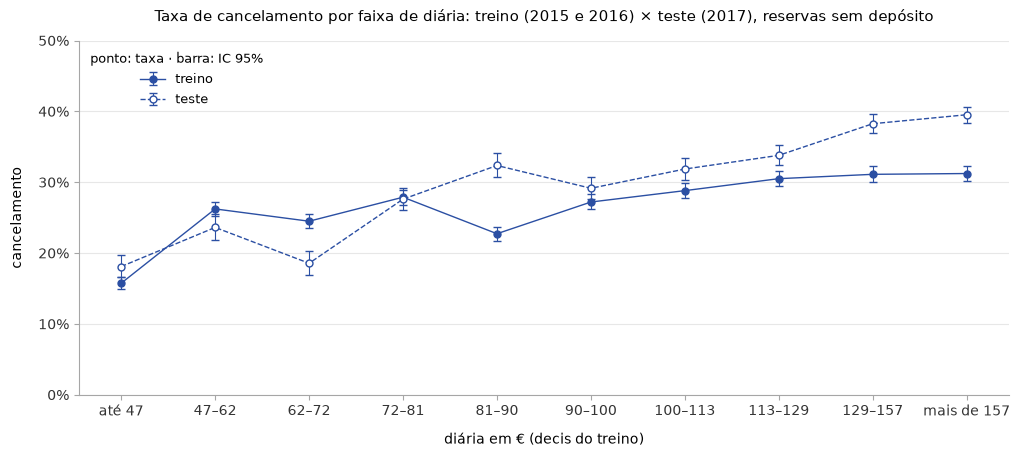

In [30]:
teste = teste.assign(
    segmento=teste['market_segment'].replace({'Complementary': 'Outros', 'Aviation': 'Outros', 'Undefined': 'Outros'}))

from matplotlib.ticker import PercentFormatter

# diária: decis do treino aplicados aos dois períodos (o corte é o mesmo, o preço é que muda)
cortes_adr = treino['adr'].quantile(np.linspace(0, 1, 11)).to_numpy().copy()
cortes_adr[0], cortes_adr[-1] = -np.inf, np.inf
por_decil = pd.concat({
    periodo: taxa_por_nivel(dados.assign(decil_adr=pd.cut(dados['adr'], cortes_adr)), 'decil_adr')[['n', 'taxa', 'ic_inf', 'ic_sup']]
    for periodo, dados in [('treino', treino), ('teste', teste)]
}, axis=1)
display(por_decil.round(4))

fig, ax = plt.subplots(figsize=(12, 4.6))
posicoes = np.arange(len(por_decil))
for periodo, estilo in [('treino', dict(marker='o', linestyle='-')), ('teste', dict(marker='o', linestyle='--', markerfacecolor='white'))]:
    taxa = por_decil[(periodo, 'taxa')]
    erro = [taxa - por_decil[(periodo, 'ic_inf')], por_decil[(periodo, 'ic_sup')] - taxa]
    ax.errorbar(posicoes, taxa, yerr=erro, capsize=3, color=CORES['principal'], label=periodo,
                linewidth=1, elinewidth=0.8, markersize=5, **estilo)
rotulos = [f'{i.left:.0f}–{i.right:.0f}' for i in por_decil.index]
rotulos[0], rotulos[-1] = f'até {por_decil.index[0].right:.0f}', f'mais de {por_decil.index[-1].left:.0f}'
ax.set_xticks(posicoes, rotulos)
ax.set_ylim(0, 0.5)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel('diária em € (decis do treino)')
ax.set_ylabel('cancelamento')
ax.set_title('Taxa de cancelamento por faixa de diária: treino (2015 e 2016) × teste (2017), reservas sem depósito')
ax.legend(frameon=False, title='ponto: taxa · barra: IC 95%', title_fontsize=9, fontsize=9)
plt.show()

**Leitura.**

- **A relação da diária com o cancelamento muda em 2017.** Nas duas faixas mais caras do treino (acima de 129), o teste cancela 38,3% e 39,5%, contra 31,1% e 31,2% no treino. No meio da escala, as faixas sobem e descem sem padrão: de 62 a 72, 18,6% no teste contra 24,5%; de 81 a 90, 32,4% contra 22,7%.

In [31]:
# preço: a mediana da diária sobe nos dois hotéis
pd.concat({'treino': treino.groupby('hotel')['adr'].median(), 'teste': teste.groupby('hotel')['adr'].median()}, axis=1)

,treino,teste
hotel,,
City Hotel,96.0,114.4
Resort Hotel,72.0,88.0


**Leitura.**

- **Parte disso é preço.** A diária mediana sobe de 96 para 114,4 no hotel urbano e de 72 para 88 no resort. Com as faixas fixas do treino, uma mesma faixa em euros junta reservas diferentes em cada ano: a faixa acima de 157 tem 6.777 reservas no treino e 7.024 no teste, que tem pouco mais da metade das reservas.
- **Consequência:** a diária em euros não serve como está. A seção 4 confere se ela acrescenta algo depois de controlar segmento e antecedência, que também mudam em 2017. Se não acrescentar, sai.

In [32]:
# perfil × comportamento: a taxa do treino em cada grupo de reservas, com o perfil de 2017
grupos_perfil = ['hotel', 'segmento', 'faixa_lead', 'temporada']
def com_perfil(dados):
    return dados.assign(
        faixa_lead=pd.cut(dados['lead_time'], [-1, 7, 30, 90, 180, np.inf],
                          labels=['até 7', '8–30', '31–90', '91–180', 'mais de 180']),
        temporada=np.where(dados['arrival_date_month'].isin(['July', 'August']), 'jul–ago', 'resto'))

taxa_grupo_treino = com_perfil(treino).groupby(grupos_perfil, observed=True)['is_canceled'].mean()
perfil_teste = com_perfil(teste).groupby(grupos_perfil, observed=True).size()
taxa_aplicada = taxa_grupo_treino.reindex(perfil_teste.index)
cobertos = taxa_aplicada.notna()
esperada_2017 = (perfil_teste[cobertos] * taxa_aplicada[cobertos]).sum() / perfil_teste[cobertos].sum()

alta = teste['is_canceled'].mean() - treino['is_canceled'].mean()
print(f"Parte da alta explicada só pelo perfil: {(esperada_2017 - treino['is_canceled'].mean()) / alta:.0%}")
print(f"Reservas de 2017 em grupos que existem no treino: {perfil_teste[cobertos].sum() / perfil_teste.sum():.1%}")
pd.Series({
    'treino (taxa real)': treino['is_canceled'].mean(),
    '2017 com as taxas do treino (só o perfil muda)': esperada_2017,
    '2017 (taxa real)': teste['is_canceled'].mean(),
}).to_frame('cancelamento').round(4)

Parte da alta explicada só pelo perfil: 69%
Reservas de 2017 em grupos que existem no treino: 100.0%


,cancelamento
treino (taxa real),0.2658
2017 com as taxas do treino (só o perfil muda),0.3018
2017 (taxa real),0.3178


**Leitura.**

- **Cerca de 70% da alta de 2017 vem da mudança no perfil das reservas.** Aplicando as taxas do treino de cada grupo (hotel × segmento × faixa de antecedência × temporada) ao perfil de 2017, a taxa esperada seria 30,2%. A real foi 31,8%, e o treino tinha 26,6%: o perfil explica 69% dos 5,2 pontos de alta. Todas as reservas de 2017 caem em grupos que existem no treino.
- **O resto, cerca de 1,6 ponto, é cancelamento maior dentro do mesmo perfil.** É a parte que o modelo não capta e que aparece na calibração.

In [33]:
# onde a taxa mudou dentro do perfil: segmento e antecedência, treino × teste
def taxa_e_peso(variavel, dados_treino, dados_teste):
    return pd.DataFrame({
        'pct_treino': dados_treino[variavel].value_counts(normalize=True),
        'pct_teste': dados_teste[variavel].value_counts(normalize=True),
        'taxa_treino': dados_treino.groupby(variavel, observed=True)['is_canceled'].mean(),
        'taxa_teste': dados_teste.groupby(variavel, observed=True)['is_canceled'].mean(),
    })

taxa_e_peso('segmento', treino, teste).sort_values('pct_teste', ascending=False).round(4)

,pct_treino,pct_teste,taxa_treino,taxa_teste
segmento,,,,
Online TA,0.4962,0.6197,0.3388,0.4085
Direct,0.1168,0.1265,0.1520,0.1534
Offline TA/TO,0.2157,0.1236,0.1729,0.1689
Groups,0.1092,0.0840,0.3159,0.2043
Corporate,0.0526,0.0375,0.1309,0.1534
Outros,0.0095,0.0086,0.1358,0.1683


**Leitura.**

- **A agência online explica a maior parte da mudança.** Passa de 49,6% para 62,0% das reservas, e a taxa dela sobe de 33,9% para 40,9%. Nos grupos, a taxa cai de 31,6% para 20,4%; nos outros segmentos, quase não muda.

In [34]:
taxa_e_peso('faixa_lead', com_perfil(treino), com_perfil(teste)).round(4)

,pct_treino,pct_teste,taxa_treino,taxa_teste
faixa_lead,,,,
até 7,0.2024,0.1574,0.0950,0.0819
8–30,0.1803,0.1690,0.2483,0.2850
31–90,0.2753,0.2302,0.3078,0.3543
91–180,0.1938,0.2486,0.3338,0.3707
mais de 180,0.1481,0.1949,0.3538,0.4264


**Leitura.**

- **No total, a taxa sobe em todas as faixas de antecedência a partir de 8 dias** (de 3,7 a 7,2 pontos) e cai um pouco nas reservas de até 7 dias (de 9,5% para 8,2%).

In [35]:
# só a agência online
online_treino = com_perfil(treino).query("segmento == 'Online TA'")
online_teste = com_perfil(teste).query("segmento == 'Online TA'")
taxa_e_peso('faixa_lead', online_treino, online_teste).round(4)

,pct_treino,pct_teste,taxa_treino,taxa_teste
faixa_lead,,,,
até 7,0.1718,0.1093,0.0954,0.0854
8–30,0.2045,0.1778,0.3096,0.3377
31–90,0.3154,0.2570,0.3826,0.4217
91–180,0.2139,0.2659,0.4270,0.4671
mais de 180,0.0944,0.1899,0.4994,0.5610


**Leitura.**

- **Dentro da agência online, a antecedência também se alonga.** As reservas com mais de 180 dias passam de 9,4% para 19,0%. E a taxa sobe em todas as faixas a partir de 8 dias, de 2,8 a 6,2 pontos: com mais de 180 dias, de 49,9% para 56,1%.
- **O que isso muda:**
  - com segmento e antecedência no modelo, a maior parte da alta de 2017 é captada. A previsão para 2017 deve sair baixa em cerca de 1,6 ponto, e não em 5;
  - a ordem das reservas quase se mantém: na antecedência e na agência online, quem cancelava mais no treino continua cancelando mais em 2017. A exceção são os grupos, que caem de 31,6% para 20,4% e passam a ficar abaixo da média;
  - a interação agência online × antecedência fica para a seção 4: dentro da agência online, a antecedência separa muito mais (de 8,5% a 56,1% no teste) do que na base toda.

## Decisões para o grupo

*Seção temporária: cada ponto sai daqui quando o grupo decidir. A comparação completa com os notebooks do grupo está em `comparacao_decisoes.md`. Os pontos de escopo e limpeza estão no fim do `01_exploratoria.ipynb`.*

| # | Decisão | Proposta deste notebook | Evidência | Notebooks do grupo |
| --- | --- | --- | --- | --- |
| 1 | **Faixas de antecedência** | Até 7, 8–30, 31–90, 91–180 e mais de 180 dias, com 31–90 como referência | 3.1 | Mesmas faixas |
| 2 | **Faixas de noites** | Até 1 (com as zero noites), 2–3, 4–7 e mais de 7, com 2–3 como referência; juntar 4–7 e mais de 7 se o modelo não as separar | 3.1 | Dicionário: mesmas faixas. Notebook 03: zero noites numa faixa própria |
| 3 | **`previous_cancellations`** | Sai: 1 cancelamento anterior cancela 92,4% no treino e 17,5% no teste | 3.1 | Testar: já cancelou × nunca cancelou |
| 4 | **Crianças e bebês** | "Com criança" só com `children`; `babies` sai (com bebê cancela 20,6%, contra 26,6% sem) | 3.1 | `com_crianca` soma crianças e bebês |
| 5 | **`meal`** | Testar com quatro níveis: BB (referência), com pensão (HB e FB), SC e Undefined | 3.2 | Sem refeição (SC e Undefined) × com refeição |
| 6 | **Temporadas** | Duas: julho e agosto × resto do ano | 3.2 | Três: jul–ago, abr–jun e set–mar |
| 7 | **`customer_type`** | A decidir na seção 4: entra ou sai e, se entrar, o destino do nível Group | 3.2 | Entra |
| 8 | **`company`** | Testar a binária "paga por empresa" | 3.2 | Sai |
| 9 | **`adr`** | Em euros, não serve como está; a seção 4 decide se entra | 3.3 | Entra como número |
| 10 | **Leitura da alta de 2017** | 69% vem da mudança no perfil das reservas | 3.3 | Notebook 03: "sobretudo comportamento". Conferir se a diferença vem dos grupos usados em cada decomposição |